(sec-1-1)=
# 1.1 What Is a Biomedical Signal?

When I look at an ECG, I see a recording of something happening inside the body. The peaks and waves tell us about the heart's electrical activity, but the recording also contains breathing, movement, and noise from the measurement itself. Learning signal processing means learning how to separate these contributions and explain what the numbers represent.

I start here with the signals themselves. We will plot a few recordings, check their units, and connect what we see to the underlying physiology. There is no need to recognize every waveform yet. For now, the useful questions are simple: what did we measure, how was it recorded, and what would we like to learn from it?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
import mne
from scipy import signal
from matplotlib.patches import FancyBboxPatch

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
mne.set_log_level("ERROR")
rng = np.random.default_rng(42)

(sec-1-1-1)=
## 1.1.1 Signals as Windows on Physiology

A **biomedical signal** is a measurable quantity, usually varying in time, that reflects the state or the function of a physiological system. The definition has two halves and both matter. The first half, *measurable*, means that a sensor turns some physical quantity (a potential difference, a pressure, an amount of light) into a number we can store. The second half, *reflects physiological function*, means the quantity is interesting only because it tells us something about the body: the ECG matters because it reflects the electrical activation of the heart, not because millivolts are interesting in themselves.

It helps to separate three things that are easy to blur together. There is the **physiological process** (the depolarization of the ventricles), the **physical quantity** it produces (a distribution of electric potential over the torso), and the **recorded signal** (the voltage between two electrodes, amplified, filtered and sampled). Every step from the first to the third adds distortion and noise, and much of signal processing is an attempt to undo or at least account for that path. Section 1.2 follows the first step, from ions to body-surface potentials, and Section 1.3 follows the rest, from electrode to computer.

Mathematically, a signal is a function. A continuous-time signal $x(t)$ assigns a value to every instant $t$; once it has been sampled every $T_s = 1/f_s$ seconds it becomes a sequence $x[n] = x(nT_s)$. Images are signals too, functions of two or three spatial coordinates, but in this book I deal almost entirely with one-dimensional time series, which is what physiological monitoring produces.

Before going further, here is the signal that will accompany us through the book: three seconds of lead MLII from record 100 of the MIT-BIH Arrhythmia Database {cite:p}`moody2001,goldberger2000`. I use this record as the default example because it is clean, mostly normal sinus rhythm, and has every beat annotated by cardiologists, which lets us check our algorithms against an expert reference.

In [2]:
rec = wfdb.rdrecord("../data/mitdb/100", sampfrom=0, sampto=360 * 4, channels=[0])
fs = rec.fs
ecg = rec.p_signal[:, 0]
t = np.arange(ecg.size) / fs

ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=0, sampto=ecg.size)
r_peaks = ann.sample[np.isin(ann.symbol, ["N", "A", "V"])]

print(f"Sampling rate      : {fs} Hz")
print(f"Samples loaded     : {ecg.size} ({ecg.size / fs:.1f} s)")
print(f"Lead               : {rec.sig_name[0]} in {rec.units[0]}")
print(f"Annotated R peaks  : {r_peaks.size}")

Sampling rate      : 360 Hz
Samples loaded     : 1440 (4.0 s)
Lead               : MLII in mV
Annotated R peaks  : 5


The P wave, the QRS complex and the T wave are the three landmarks every ECG reader looks for. The P wave reflects the depolarization of the atria, the QRS complex the much larger depolarization of the ventricles, and the T wave their repolarization; Chapter 11 explains their origin in detail. In the code below we locate the P and T peaks of one beat by searching for the maximum in short windows before and after the annotated R peak.

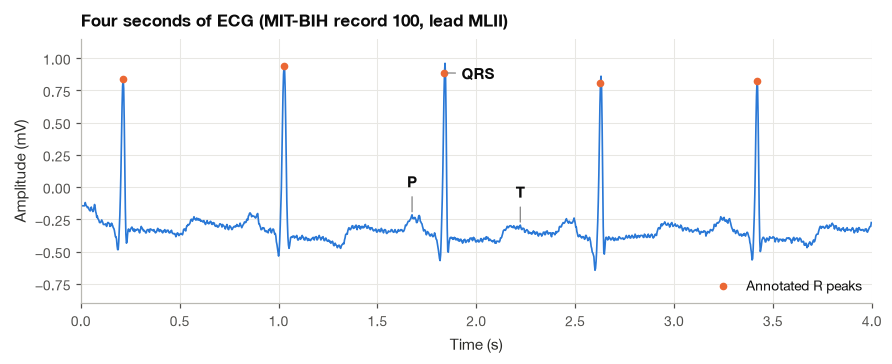

In [3]:
r = r_peaks[2]
p_win = np.arange(r - int(0.25 * fs), r - int(0.08 * fs))
t_win = np.arange(r + int(0.15 * fs), r + int(0.45 * fs))
p_peak = p_win[np.argmax(ecg[p_win])]
t_peak = t_win[np.argmax(ecg[t_win])]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(t, ecg, color=C[0], lw=1.1)
ax.plot(r_peaks / fs, ecg[r_peaks], "o", color=C[1], ms=4, label="Annotated R peaks")
for idx, label, dx in [(p_peak, "P", 0), (r, "QRS", 22), (t_peak, "T", 0)]:
    ax.annotate(label, (idx / fs, ecg[idx]), xytext=(dx, 18 if dx == 0 else -4), textcoords="offset points",
                ha="center", fontsize=10, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="0.5", lw=0.8))
ax.set(xlim=(0, 4), ylim=(-0.9, 1.15), xlabel="Time (s)", ylabel="Amplitude (mV)",
       title="Four seconds of ECG (MIT-BIH record 100, lead MLII)")
ax.legend(loc="lower right")
plt.show()

Even this short strip shows the typical scale of the problem. The R peaks rise about 1.2 mV above the baseline, the P wave little more than a tenth of a millivolt, and the baseline itself sits at a negative offset of about −0.35 mV that has nothing to do with the heart. Those are the numbers we will have to work with. Notice also that the orange markers do not always sit exactly on the tallest sample: the annotators marked a fiducial point of each beat, not its numerical maximum, a detail that matters when we later compare automatic detectors against these labels.

(sec-1-1-2)=
## 1.1.2 A Taxonomy by Physical Origin

The most useful first classification of biomedical signals is by the physical mechanism that produces them, because the mechanism dictates the sensor, the amplitude, the frequency content and the typical artifacts {cite:p}`rangayyan2015,semmlow2014`.

**Bioelectric signals** arise from ionic currents in excitable tissue, the subject of Section 1.2. They are recorded with electrodes, and they are the largest and most studied group: the **electrocardiogram** (ECG) from the heart, the **electroencephalogram** (EEG) from the cortex, measured on the scalp, the **electromyogram** (EMG) from skeletal muscle, recorded either with surface electrodes (sEMG) or with a needle inserted into the muscle, the **electrooculogram** (EOG), which tracks eye movements through the standing potential between cornea and retina, and the **electroretinogram** (ERG), the response of the retina to a flash of light. Closer to the sources, the **electrocorticogram** (ECoG) is recorded from electrodes placed directly on the cortex during neurosurgery, and the **local field potential** (LFP) from microelectrodes inside the brain tissue. These invasive recordings are larger and spatially sharper than the scalp EEG because the skull and scalp no longer stand in between.

**Biomagnetic signals** are the magnetic fields produced by the same ionic currents. The magnetoencephalogram (MEG) and magnetocardiogram (MCG) are tiny: the field of the heart is of the order of tens of picotesla and that of the brain is smaller again, against an Earth field of about 50 µT, so they are measured with superconducting sensors in magnetically shielded rooms {cite:p}`malmivuo1995`.

**Biomechanical signals** come from motion, force, pressure or flow. Arterial blood pressure measured through a catheter, blood flow measured with ultrasound, chest-wall movement during breathing and body acceleration recorded by the accelerometer in a wearable all belong here.

**Bioacoustic signals** are the mechanical vibrations that reach the body surface as sound: heart sounds and murmurs (the phonocardiogram, PCG), lung sounds heard through a stethoscope, joint sounds, and the sounds of swallowing.

**Biochemical signals** report the concentration of a substance: blood glucose, the partial pressures of oxygen and carbon dioxide in blood, blood pH. They usually change slowly, over minutes or hours, and are measured with chemical sensors such as the enzyme electrode in a continuous glucose monitor.

**Bio-optical signals** are obtained by shining light into tissue and measuring what comes back. The **photoplethysmogram** (PPG), the waveform behind every pulse oximeter and smartwatch heart-rate reading, tracks the small change in light absorption as each heartbeat fills the arterioles. Functional near-infrared spectroscopy (fNIRS) uses the same principle on the head to follow changes in cortical blood oxygenation.

A seventh group cuts across these categories: signals that exist only because we inject energy into the body. Impedance pneumography, used in the BIDMC recordings below, passes a small high-frequency current across the chest and measures how the impedance changes as the lungs fill with air. The PPG is in this group too, since it requires a light source.

The table below collects typical amplitude and frequency ranges for the signals we meet most often. The values are indicative, compiled from {cite:t}`webster2010`, {cite:t}`rangayyan2015` and {cite:t}`semmlow2014`; real recordings depend on electrode placement, skin preparation, the subject and the purpose of the measurement. The diagnostic ECG bandwidth of 0.05–150 Hz, for example, is what a resting 12-lead recorder must preserve, while a bedside monitor typically keeps only 0.5–40 Hz.

| Signal | Origin | Typical amplitude | Main frequency content | Typical sensor |
|---|---|---|---|---|
| ECG (body surface) | bioelectric | 0.5–4 mV | 0.05–150 Hz | Ag/AgCl skin electrodes |
| EEG (scalp) | bioelectric | 2–100 µV | 0.5–100 Hz | scalp electrodes |
| Surface EMG | bioelectric | 0.05–5 mV | 10–500 Hz | skin electrodes over the muscle |
| Needle EMG | bioelectric | 0.1–5 mV | 10 Hz–10 kHz | concentric needle electrode |
| EOG | bioelectric | 0.05–3.5 mV | DC–50 Hz | electrodes beside the eyes |
| PPG | bio-optical | small pulsatile part on a large steady level (a.u.) | 0.5–10 Hz | LED and photodiode |
| Respiration | biomechanical | depends on the sensor | 0.1–1 Hz | impedance, chest belt, airflow |
| Arterial blood pressure | biomechanical | about 60–140 mmHg | DC–50 Hz | catheter and pressure transducer |
| Phonocardiogram | bioacoustic | depends on the sensor | about 20–1000 Hz | contact microphone |
| Blood glucose | biochemical | about 4–8 mmol/L (healthy) | changes over minutes to hours | enzyme electrode |

A picture makes the overlaps easier to see. The next figure places the five bioelectric signals on logarithmic amplitude and frequency axes.

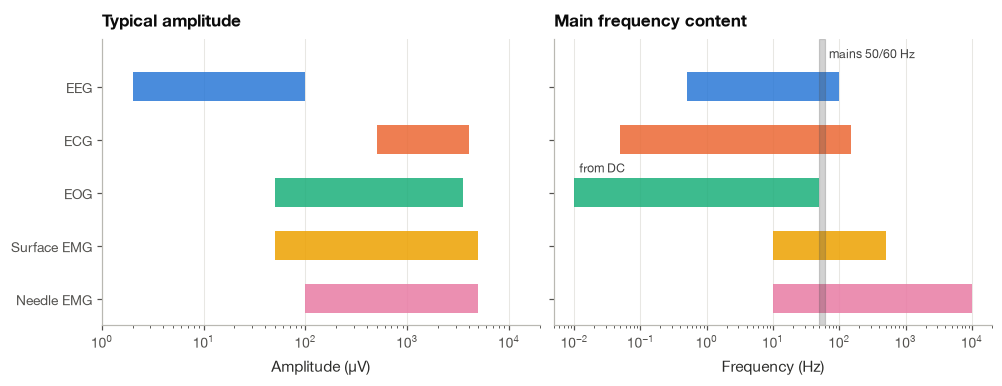

In [4]:
bioelectric = pd.DataFrame(
    [("EEG", 2, 100, 0.5, 100), ("ECG", 500, 4000, 0.05, 150), ("EOG", 50, 3500, 0.01, 50),
     ("Surface EMG", 50, 5000, 10, 500), ("Needle EMG", 100, 5000, 10, 10_000)],
    columns=["signal", "a_min_uV", "a_max_uV", "f_min_Hz", "f_max_Hz"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
y = np.arange(len(bioelectric))[::-1]
for k, row in bioelectric.iterrows():
    axes[0].barh(y[k], row.a_max_uV - row.a_min_uV, left=row.a_min_uV, height=0.55, color=C[k], alpha=0.85)
    axes[1].barh(y[k], row.f_max_Hz - row.f_min_Hz, left=row.f_min_Hz, height=0.55, color=C[k], alpha=0.85)
axes[0].set(xscale="log", xlim=(1, 2e4), xlabel="Amplitude (µV)", title="Typical amplitude")
axes[0].set_yticks(y, bioelectric.signal)
axes[1].set(xscale="log", xlim=(0.005, 2e4), xlabel="Frequency (Hz)", title="Main frequency content")
axes[1].axvspan(50, 60, color="0.3", alpha=0.25)
axes[1].text(70, y[0] + 0.62, "mains 50/60 Hz", fontsize=8, color="0.25", va="center")
axes[0].set_ylim(-0.5, y[0] + 0.9)
axes[1].text(0.012, y[2] + 0.38, "from DC", fontsize=8, color="0.25")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.show()

Two facts stand out. First, the amplitudes span more than three orders of magnitude, from a few microvolts of EEG to several millivolts of EMG, and all of them are tiny compared with the volts that an analog-to-digital converter expects; amplification is unavoidable. Second, the frequency ranges overlap heavily. The power-line frequency of 50 or 60 Hz falls inside every one of them, muscle activity overlaps the upper part of the ECG band, and eye movements overlap the lower part of the EEG band. A simple frequency-selective filter therefore cannot separate a signal from every source of interference, which is why Part IV of this book needs more than one chapter.

(sec-1-1-3)=
## 1.1.3 What Makes Biomedical Signals Difficult

Most of the signal processing in this book exists because biomedical signals share a few awkward properties. I find it useful to keep four of them in mind from the start.

**They are weak.** Microvolts and millivolts must be amplified a thousand times or more before they can be digitized, and the amplifier itself adds noise. The weaker the signal, the more carefully the acquisition chain must be designed, as Section 1.3 shows.

**They are noisy and full of artifacts.** Some interference comes from outside the body: power-line pickup, radio-frequency fields, the electrode–skin interface shifting when the subject moves. Some comes from the body itself, and this physiological interference is harder to deal with because it often overlaps the signal of interest in both time and frequency. Muscle activity contaminates the ECG, eye blinks contaminate the EEG, and the mother's ECG dominates an abdominal recording of the fetal heart, as we will see in the gallery below. In the ECG specifically, baseline wander from breathing, electrode-motion artifact and muscle noise are so common that Chapter 12 is devoted to removing them step by step.

**They vary.** Two healthy people have different heart rates, different QRS amplitudes and different alpha frequencies, a property called **inter-subject variability**. The same person also changes from moment to moment, **intra-subject variability**: the interval between heartbeats fluctuates with every breath, and the EEG changes with attention and drowsiness. Any method that works only on the one recording it was tuned on is of little use, and a large part of evaluating biomedical algorithms (Chapter 27) is about testing them on subjects they have never seen.

**They are nonstationary.** The statistical properties of the signal, its mean, its variance, its frequency content, change over time. A heart rate that is constant at rest rises during exercise, an arrhythmia can start and stop within seconds, and the EEG of a person falling asleep slows down over minutes. Many classical tools, the Fourier transform among them, implicitly assume that the signal's properties do not change during the analysis window. When they do, we need either short windows or the time–frequency methods of Part VII.

We will see each of these properties in real data before the end of the section.

(sec-1-1-4)=
## 1.1.4 A Gallery of Real Signals

Definitions become concrete once we look at actual recordings. All the data used in this book come from PhysioNet {cite:p}`goldberger2000` and are stored in the `data/` folder of the book repository; [Appendix B](../appendix/b_datasets.ipynb) describes each database. In this subsection we load six signals of different origin and plot them on a common layout. The ECG comes first because it is the main thread of the book; the others are there to show how much the signals differ.

### Step 1: Load a stretch of each recording

The MIT-BIH, BIDMC {cite:p}`pimentel2017` and EMG records are in the WFDB format and are read with the `wfdb` package. The EEG {cite:p}`schalk2004` and the abdominal fetal ECG {cite:p}`jezewski2012` are stored as EDF files, which we read with MNE-Python {cite:p}`gramfort2013`. A small helper reads one named channel from a WFDB record; it strips the trailing comma that the BIDMC files attach to their channel names.

In [5]:
def read_wfdb_channel(path, channel, t0=0.0, t1=None):
    """Return one named channel of a WFDB record between t0 and t1 seconds, and fs."""
    hdr = wfdb.rdheader(path)
    sampto = hdr.sig_len if t1 is None else int(t1 * hdr.fs)
    rec = wfdb.rdrecord(path, sampfrom=int(t0 * hdr.fs), sampto=sampto)
    names = [s.strip(",") for s in rec.sig_name]
    return rec.p_signal[:, names.index(channel)], rec.fs


def read_edf_channel(path, channel, t0=0.0, t1=None):
    """Return one channel of an EDF file in microvolts between t0 and t1 seconds, and fs."""
    raw = mne.io.read_raw_edf(path, preload=True)
    if raw.ch_names[0].endswith("."):
        mne.datasets.eegbci.standardize(raw)        # 'O1..' -> 'O1'
    x = raw.get_data(picks=[channel], units="uV", tmin=t0, tmax=t1)[0]
    return x, raw.info["sfreq"]


recordings = {
    "ECG":          read_wfdb_channel("../data/mitdb/100", "MLII", 0, 60),
    "EEG":          read_edf_channel("../data/eegmmidb/S001R02.edf", "O1"),
    "Needle EMG":   read_wfdb_channel("../data/emgdb/emg_healthy", "EMG"),
    "Abdominal ECG": read_edf_channel("../data/adfecgdb/r01.edf", "Abdomen_1", 0, 60),
    "PPG":          read_wfdb_channel("../data/bidmc/bidmc01", "PLETH", 0, 120),
    "Respiration":  read_wfdb_channel("../data/bidmc/bidmc01", "RESP", 0, 120),
}
for name, (x, fs_x) in recordings.items():
    print(f"{name:14s} fs = {fs_x:6.0f} Hz   {x.size:6d} samples   {x.size / fs_x:6.1f} s")

ECG            fs =    360 Hz    21600 samples     60.0 s
EEG            fs =    160 Hz     9760 samples     61.0 s
Needle EMG     fs =   4000 Hz    50860 samples     12.7 s
Abdominal ECG  fs =   1000 Hz    60000 samples     60.0 s
PPG            fs =    125 Hz    15000 samples    120.0 s
Respiration    fs =    125 Hz    15000 samples    120.0 s


### Step 2: Plot a meaningful window of each

Each signal needs its own time window. Four seconds show three or four heartbeats or forty cycles of alpha rhythm, but they would show less than one breath, and half a second is already enough to see dozens of motor-unit potentials in the needle EMG. For the two signals that have reference annotations, we also mark the events: the R peaks of record 100 and the fetal QRS complexes of the abdominal recording, which were located on a simultaneous direct scalp electrode.

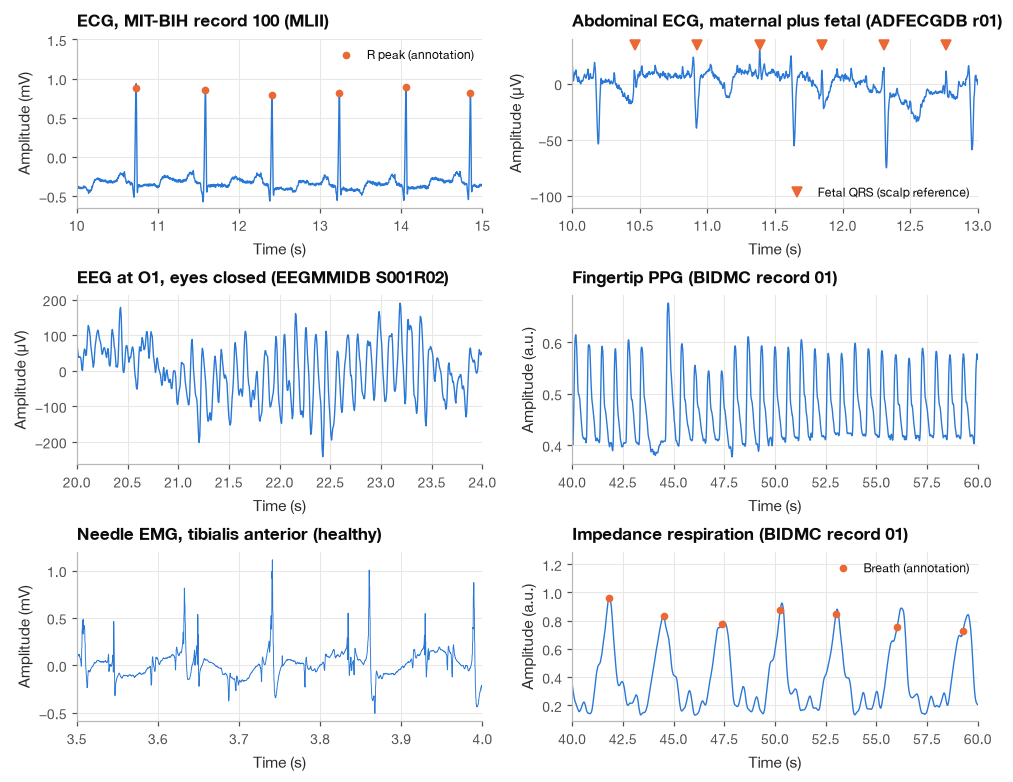

In [6]:
windows = {"ECG": (10, 15), "EEG": (20, 24), "Needle EMG": (3.5, 4.0),
           "Abdominal ECG": (10, 13), "PPG": (40, 60), "Respiration": (40, 60)}
units = {"ECG": "mV", "EEG": "µV", "Needle EMG": "mV", "Abdominal ECG": "µV",
         "PPG": "a.u.", "Respiration": "a.u."}
titles = {"ECG": "ECG, MIT-BIH record 100 (MLII)",
          "EEG": "EEG at O1, eyes closed (EEGMMIDB S001R02)",
          "Needle EMG": "Needle EMG, tibialis anterior (healthy)",
          "Abdominal ECG": "Abdominal ECG, maternal plus fetal (ADFECGDB r01)",
          "PPG": "Fingertip PPG (BIDMC record 01)",
          "Respiration": "Impedance respiration (BIDMC record 01)"}

mitdb_ann = wfdb.rdann("../data/mitdb/100", "atr")
fetal_qrs = wfdb.rdann("../data/adfecgdb/r01.edf", "qrs").sample / 1000
breaths = wfdb.rdann("../data/bidmc/bidmc01", "breath")
breath_times = breaths.sample[np.array(breaths.aux_note) == "ann1"] / 125

fig, axes = plt.subplots(3, 2, figsize=(9, 7))
for ax, name in zip(axes.T.ravel(), windows):
    x, fs_x = recordings[name]
    t0, t1 = windows[name]
    tx = np.arange(x.size) / fs_x
    sel = (tx >= t0) & (tx < t1)
    ax.plot(tx[sel], x[sel], color=C[0], lw=0.9 if name != "Needle EMG" else 0.6)
    if name == "ECG":
        r = mitdb_ann.sample[(mitdb_ann.sample >= t0 * 360) & (mitdb_ann.sample < t1 * 360)]
        ax.plot(r / 360, x[r], "o", color=C[1], ms=4, label="R peak (annotation)")
    if name == "Abdominal ECG":
        fq = fetal_qrs[(fetal_qrs >= t0) & (fetal_qrs < t1)]
        ax.plot(fq, np.full(fq.size, x[sel].max() * 1.15), "v", color=C[1], ms=6,
                label="Fetal QRS (scalp reference)")
    if name == "Respiration":
        bt = breath_times[(breath_times >= t0) & (breath_times < t1)]
        ax.plot(bt, x[np.round(bt * 125).astype(int)], "o", color=C[1], ms=4, label="Breath (annotation)")
    if ax.get_legend_handles_labels()[0]:
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo - 0.25 * (hi - lo) * (name == "Abdominal ECG"), hi + 0.3 * (hi - lo) * (name != "Abdominal ECG"))
        ax.legend(loc="lower right" if name == "Abdominal ECG" else "upper right", fontsize=8)
    ax.set(title=titles[name], xlabel="Time (s)", ylabel=f"Amplitude ({units[name]})", xlim=(t0, t1))
plt.show()

### Step 3: Measure amplitude and frequency content

Looking is the first step; measuring is the second. For each signal we compute three simple descriptors over the whole loaded stretch: a typical peak-to-peak amplitude (the distance between the 0.5th and 99.5th percentiles, which ignores a few extreme samples), the root-mean-square value after removing the mean, and the **median frequency**, the frequency below which half of the signal power lies. The median frequency uses Welch's power spectrum estimate, which I treat as a black box here; Section 7.3 derives it properly.

In [7]:
def median_frequency(x, fs, seg_s=16):
    """Frequency (Hz) below which half of the power lies, from a Welch PSD estimate."""
    f, pxx = signal.welch(x - x.mean(), fs=fs, nperseg=min(x.size, int(seg_s * fs)))
    cumulative = np.cumsum(pxx)
    return f[np.searchsorted(cumulative, 0.5 * cumulative[-1])]


rows = []
for name, (x, fs_x) in recordings.items():
    lo, hi = np.percentile(x, [0.5, 99.5])
    rows.append({"signal": name, "unit": units[name], "fs (Hz)": int(fs_x),
                 "peak-to-peak": round(hi - lo, 3), "RMS": round(np.std(x), 3),
                 "median freq. (Hz)": round(median_frequency(x, fs_x), 2)})
descriptors = pd.DataFrame(rows).set_index("signal")
descriptors

,unit,fs (Hz),peak-to-peak,RMS,median freq. (Hz)
signal,,,,,
ECG,mV,360,1.420,0.176,12.50
EEG,µV,160,407.205,78.528,9.75
Needle EMG,mV,4000,0.567,0.082,64.25
Abdominal ECG,µV,1000,87.202,13.015,7.50
PPG,a.u.,125,0.338,0.067,1.50
Respiration,a.u.,125,1.000,0.298,0.38


(sec-1-1-5)=
## 1.1.5 What to Look For: Amplitude, Frequency, Morphology, Stationarity

The gallery and the table already illustrate the four questions I ask of any new biomedical signal.

**Amplitude.** How large is it, and in what units? The ECG of record 100 swings by about 1.4 mV, the scalp EEG by about 400 µV with the eyes closed, and the abdominal ECG by less than 90 µV, of which the fetal contribution is a small fraction. Amplitude decides the gain of the amplifier and the resolution of the converter, and a sudden change in amplitude is often the first sign of an artifact such as a loose electrode. The PPG and the impedance respiration signal have no physical unit at all: the BIDMC files store them in normalized units, a reminder that for some signals only the shape and timing are meaningful.

**Frequency.** How fast does it change? The median frequencies in the table run from 0.38 Hz for breathing (about 23 breaths per minute) to 64 Hz for the needle EMG, more than two orders of magnitude, and the highest frequencies present set the minimum sampling rate. It is no accident that the EMG was recorded at 4000 Hz while the BIDMC signals were stored at 125 Hz: the EMG's median is modest, but its spectrum extends into the kilohertz range. The ECG is an instructive case. The heart beats only about 1.3 times per second, yet the median frequency is 12.5 Hz, because a large share of the power sits in the steep edges of the QRS complexes. The P and T waves are slow, the QRS complex is fast, and a recorder must preserve both. A single number never tells the whole story about frequency content, which is why Part III builds the full machinery of spectra.

**Morphology.** What is the shape of the repeating events? Clinicians interpret the ECG largely by shape: the width of the QRS complex, the height of the ST segment, the polarity of the T wave. In the abdominal recording, the large maternal complexes and the small, narrow fetal complexes have different shapes and different rates, and that difference is what makes it possible to separate them later (Chapter 25). Shape is also how we recognize many artifacts: no heart produces a perfectly flat top, so a clipped waveform is a recording problem.

**Stationarity.** Do the properties stay the same over time? The 4-s windows in the gallery hide this question, which is why the next two subsections look at longer stretches.

(sec-1-1-6)=
## 1.1.6 Variability: Heart Rhythm over Thirty Minutes

The heart of a healthy person at rest does not beat like a metronome. The interval between consecutive R peaks, the **RR interval**, shortens during inspiration and lengthens during expiration, drifts with blood pressure regulation and changes with posture and mood. This beat-to-beat fluctuation is the basis of heart rate variability analysis (Section 19.2). Here we only want to see it, using the cardiologists' annotations of record 100 as a perfect beat detector.

### Step 1: Read the beat annotations

The annotation file lists every event with its sample index and a symbol. Beat symbols (N for normal, A for atrial premature, V for ventricular premature, and so on) are mixed with non-beat symbols such as `+`, which marks a rhythm change, so we keep only the beats.

In [8]:
BEAT_SYMBOLS = list("NLRBAaJSVrFejnE/fQ")

ann = wfdb.rdann("../data/mitdb/100", "atr")
symbols = np.array(ann.symbol)
is_beat = np.isin(symbols, BEAT_SYMBOLS)
beat_samples = ann.sample[is_beat]
beat_symbols = symbols[is_beat]

print(f"Annotations in file : {symbols.size}")
print(f"Beats               : {beat_samples.size}")
print("Beat types          :", {str(s): int(n) for s, n in zip(*np.unique(beat_symbols, return_counts=True))})

Annotations in file : 2274
Beats               : 2273
Beat types          : {'A': 33, 'N': 2239, 'V': 1}


### Step 2: Compute RR intervals and separate normal-to-normal intervals

An RR interval is the difference between consecutive beat times. Intervals that begin or end on an ectopic beat (here the 33 atrial premature beats and the single ventricular one) reflect the arrhythmia rather than the normal regulation of heart rate, so heart rate variability analysis uses only **normal-to-normal (NN) intervals**, those between two consecutive normal beats.

In [9]:
fs = ann.fs
rr = np.diff(beat_samples) / fs                     # s
t_rr = beat_samples[1:] / fs / 60                   # min, time of the second beat
is_nn = (beat_symbols[1:] == "N") & (beat_symbols[:-1] == "N")
nn = rr[is_nn]

print(f"NN intervals        : {nn.size}")
print(f"Mean NN interval    : {1000 * nn.mean():.0f} ms  (heart rate {60 / nn.mean():.1f} bpm)")
print(f"SD of NN intervals  : {1000 * nn.std():.0f} ms")
print(f"Range of NN         : {1000 * nn.min():.0f} to {1000 * nn.max():.0f} ms")
print(f"Shortest RR overall : {1000 * rr.min():.0f} ms (around an ectopic beat)")

NN intervals        : 2204
Mean NN interval    : 795 ms  (heart rate 75.5 bpm)
SD of NN intervals  : 36 ms
Range of NN         : 653 to 889 ms
Shortest RR overall : 522 ms (around an ectopic beat)


### Step 3: Plot the RR series and its distribution

A plot of RR interval against time is called a **tachogram**.

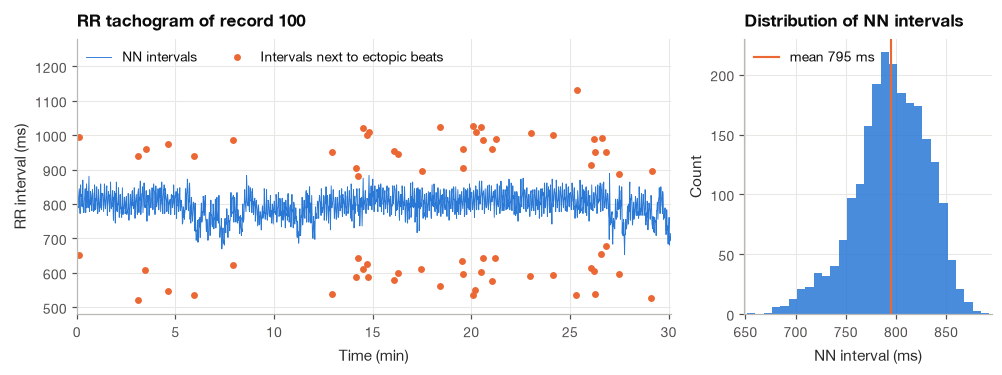

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), gridspec_kw={"width_ratios": [2.4, 1]})
ax = axes[0]
ax.plot(t_rr[is_nn], 1000 * rr[is_nn], color=C[0], lw=0.6, label="NN intervals")
ax.plot(t_rr[~is_nn], 1000 * rr[~is_nn], "o", color=C[1], ms=3.5,
        label="Intervals next to ectopic beats")
ax.set(xlabel="Time (min)", ylabel="RR interval (ms)", xlim=(0, 30.1), ylim=(480, 1280),
       title="RR tachogram of record 100")
ax.legend(loc="upper left", ncols=2)

ax = axes[1]
nn_samples = np.round(nn * fs).astype(int)
edges = (np.arange(nn_samples.min(), nn_samples.max() + 4, 3) - 0.5) / fs * 1000   # 3-sample bins
ax.hist(1000 * nn, bins=edges, color=C[0], alpha=0.85)
ax.axvline(1000 * nn.mean(), color=C[1], lw=1.4, label=f"mean {1000 * nn.mean():.0f} ms")
ax.set(xlabel="NN interval (ms)", ylabel="Count", title="Distribution of NN intervals")
ax.legend(loc="upper left")
plt.show()

Even in this calm, mostly normal recording, the NN interval wanders between roughly 650 and 890 ms, with a standard deviation of 36 ms. The fast oscillations superimposed on the slower drifts are largely respiratory sinus arrhythmia. The orange points show what an ectopic beat does: an atrial premature beat arrives early, producing a short interval, and is usually followed by a longer pause.

### Step 4: Compare different people

Intra-subject variability is one half of the picture. To see inter-subject variability, we repeat the computation for the six MIT-BIH records stored with the book. Each comes from a different patient.

In [11]:
rows = []
for record in ["100", "105", "106", "119", "203", "208"]:
    a = wfdb.rdann(f"../data/mitdb/{record}", "atr")
    sym = np.array(a.symbol)
    beats = np.isin(sym, BEAT_SYMBOLS)
    rr_rec = np.diff(a.sample[beats]) / a.fs
    rhythms = sorted({note.strip("\x00(") for note in a.aux_note if note.startswith("(")})
    rows.append({"record": record, "beats": beats.sum(),
                 "mean HR (bpm)": round(60 / rr_rec.mean(), 1),
                 "SD of RR (ms)": round(1000 * rr_rec.std()),
                 "non-normal beats (%)": round(100 * np.mean(sym[beats] != "N"), 1),
                 "rhythms": ", ".join(rhythms)})
pd.DataFrame(rows).set_index("record")

,beats,mean HR (bpm),SD of RR (ms),non-normal beats (%),rhythms
record,,,,,
100,2273,75.5,49,1.5,N
105,2572,85.5,65,1.8,N
106,2027,67.4,261,25.7,"B, N, T, VT"
119,1987,66.0,258,22.3,"B, N, T"
203,2980,99.0,200,15.1,"AFIB, AFL, T, VT"
208,2955,98.2,135,46.3,"N, T"


The mean heart rate ranges from 66 to 99 beats per minute across the six patients, and the RR standard deviation differs by a factor of five, from 49 ms in record 100 (all beats included) to more than 250 ms in records 106 and 119, where ventricular premature beats in bigeminy alternate short and long intervals. In record 203 atrial fibrillation makes the rhythm irregular throughout. A detector that assumes one heart rate, or one QRS shape, will fail on some of these patients, which is exactly why the algorithms in Chapter 19 are evaluated on whole databases rather than on a single recording.

(sec-1-1-7)=
## 1.1.7 Nonstationarity: When the Statistics Change

The table above already contains an example of nonstationarity: record 203 switches between several rhythms. The rhythm-change annotations tell us when, so we can measure how long the patient spends in each state.

In [12]:
ann203 = wfdb.rdann("../data/mitdb/203", "atr")
changes = [(s, note.strip("\x00(")) for s, note in zip(ann203.sample, ann203.aux_note)
           if note.startswith("(")]
starts = np.array([s for s, _ in changes] + [650_000])
labels = [lab for _, lab in changes]
episodes = pd.DataFrame({"rhythm": labels, "duration (s)": np.diff(starts) / ann203.fs})
summary = episodes.groupby("rhythm")["duration (s)"].agg(["count", "sum"])
summary.columns = ["episodes", "total time (s)"]
summary.round(1)

,episodes,total time (s)
rhythm,,
AFIB,21,1455.0
AFL,2,314.3
T,1,3.8
VT,21,32.5


Within half an hour this patient spends about 24 min in atrial fibrillation (AFIB) and 5 min in atrial flutter (AFL), and the fibrillation is broken up by 21 short runs of ventricular tachycardia (VT) lasting 32 s in total, plus a few seconds of ventricular trigeminy (T). Any statistic computed over the whole record, a mean heart rate or a single spectrum, would describe none of these states well.

Nonstationarity is not limited to pathology. The EEG offers a clean example in healthy people: the alpha rhythm at 8–13 Hz over the occipital cortex grows strongly when the eyes close and waxes and wanes spontaneously even with the eyes kept closed. We measure this with the EEG Motor Movement/Imagery recordings of subject S001, comparing the one-minute baseline with eyes open (run R01) and with eyes closed (run R02).

### Step 1: Isolate the alpha band

We band-pass filter channel O1 to 8–13 Hz. The filter design is the subject of Chapter 15; here a fourth-order Butterworth filter applied forwards and backwards is enough.

In [13]:
eeg_open, fs_eeg = read_edf_channel("../data/eegmmidb/S001R01.edf", "O1")
eeg_closed, _ = read_edf_channel("../data/eegmmidb/S001R02.edf", "O1")

b, a = signal.butter(4, [8, 13], btype="bandpass", fs=fs_eeg)
alpha_open = signal.filtfilt(b, a, eeg_open)
alpha_closed = signal.filtfilt(b, a, eeg_closed)
print(f"Sampling rate: {fs_eeg:.0f} Hz, length {eeg_open.size / fs_eeg:.0f} s per run")

Sampling rate: 160 Hz, length 61 s per run


### Step 2: Track the power in sliding windows

The mean of the squared band-passed signal over a 2-s window estimates the alpha power at that moment. Sliding the window forward by 0.5 s at a time gives a power track.

In [14]:
def sliding_power(x, fs, win_s=2.0, step_s=0.5):
    """Mean squared value of x in windows of win_s seconds, advanced by step_s seconds."""
    win, step = int(win_s * fs), int(step_s * fs)
    starts = np.arange(0, x.size - win + 1, step)
    power = np.array([np.mean(x[s:s + win] ** 2) for s in starts])
    return (starts + win / 2) / fs, power


tc, p_open = sliding_power(alpha_open, fs_eeg)
_, p_closed = sliding_power(alpha_closed, fs_eeg)
print(f"Median alpha power, eyes open   : {np.median(p_open):7.0f} µV²")
print(f"Median alpha power, eyes closed : {np.median(p_closed):7.0f} µV²")
print(f"Ratio closed / open             : {np.median(p_closed) / np.median(p_open):7.1f}")
print(f"Max / min within eyes-closed run: {p_closed.max() / p_closed.min():7.1f}")

Median alpha power, eyes open   :     211 µV²
Median alpha power, eyes closed :    3443 µV²
Ratio closed / open             :    16.3
Max / min within eyes-closed run:     6.9


### Step 3: Look at the strongest and weakest moments

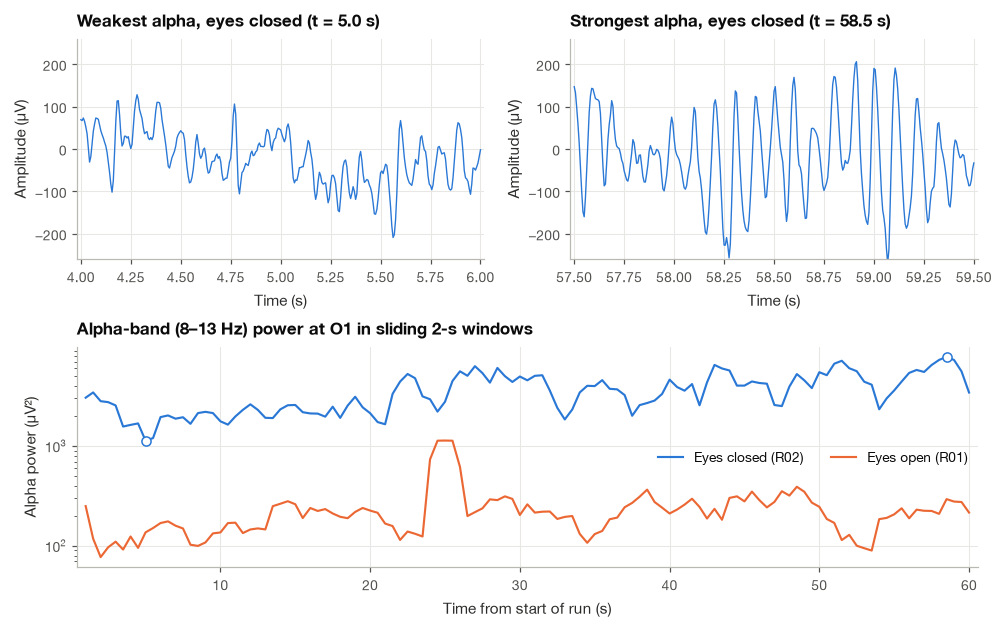

In [15]:
fig, axes = plt.subplot_mosaic([["weak", "strong"], ["track", "track"]], figsize=(9, 5.6))
tx = np.arange(eeg_closed.size) / fs_eeg
for key, idx, label in [("weak", np.argmin(p_closed), "Weakest"), ("strong", np.argmax(p_closed), "Strongest")]:
    sel = np.abs(tx - tc[idx]) <= 1.0
    axes[key].plot(tx[sel], eeg_closed[sel], color=C[0], lw=0.9)
    axes[key].set(xlabel="Time (s)", ylabel="Amplitude (µV)", ylim=(-260, 260),
                  title=f"{label} alpha, eyes closed (t = {tc[idx]:.1f} s)")

ax = axes["track"]
ax.semilogy(tc, p_closed, color=C[0], label="Eyes closed (R02)")
ax.semilogy(tc, p_open, color=C[1], label="Eyes open (R01)")
for idx in (np.argmin(p_closed), np.argmax(p_closed)):
    ax.plot(tc[idx], p_closed[idx], "o", color=C[0], ms=6, mfc="white")
ax.set(xlabel="Time from start of run (s)", ylabel="Alpha power (µV²)",
       title="Alpha-band (8–13 Hz) power at O1 in sliding 2-s windows")
ax.legend(loc="center right", ncols=2)
plt.show()

Two kinds of change are visible. Between the runs, closing the eyes raises the median alpha power by more than an order of magnitude, the classic alpha blocking first described by Hans Berger. Within the eyes-closed run, the power still swings by a factor of about seven from one moment to the next, even though nothing about the task has changed. The two 2-s excerpts in the top row come from the same minute of the same recording, yet they look like different signals. A single spectrum computed over the whole minute would average these states together. Chapter 23 introduces the tools that follow such changes properly.

(sec-1-1-8)=
## 1.1.8 From Signal to Decision: A Road Map

Every application in this book, however different, follows roughly the same pipeline. A sensor and an amplifier **acquire** the signal; filters **condition** it by removing noise and artifacts; a change of representation, most often to the frequency domain, makes its structure easier to see; algorithms **measure** features such as R-peak times, band powers or wave amplitudes; and finally a person or a classifier **interprets** those features to reach a decision. The figure below draws the pipeline for the ECG and labels each stage with the chapters that treat it.

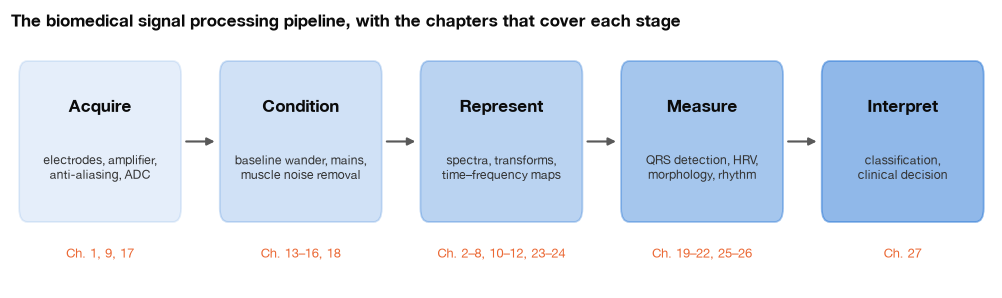

In [16]:
stages = [("Acquire", "electrodes, amplifier,\nanti-aliasing, ADC", "Ch. 1, 9, 17"),
          ("Condition", "baseline wander, mains,\nmuscle noise removal", "Ch. 13–16, 18"),
          ("Represent", "spectra, transforms,\ntime–frequency maps", "Ch. 2–8, 10–12, 23–24"),
          ("Measure", "QRS detection, HRV,\nmorphology, rhythm", "Ch. 19–22, 25–26"),
          ("Interpret", "classification,\nclinical decision", "Ch. 27")]

fig, ax = plt.subplots(figsize=(9, 2.6))
box_w, box_h, gap = 1.55, 0.9, 0.42
for k, (name, detail, chapters) in enumerate(stages):
    x0 = k * (box_w + gap)
    ax.add_patch(FancyBboxPatch((x0, 0), box_w, box_h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=C[0], alpha=0.12 + 0.1 * k, edgecolor=C[0], lw=1.2))
    ax.text(x0 + box_w / 2, 0.66, name, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x0 + box_w / 2, 0.3, detail, ha="center", va="center", fontsize=8, color="0.2")
    ax.text(x0 + box_w / 2, -0.2, chapters, ha="center", va="center", fontsize=8.5, color=C[1])
    if k < len(stages) - 1:
        ax.annotate("", xy=(x0 + box_w + gap - 0.04, box_h / 2), xytext=(x0 + box_w + 0.04, box_h / 2),
                    arrowprops=dict(arrowstyle="-|>", color="0.35", lw=1.4))
ax.set(xlim=(-0.1, len(stages) * (box_w + gap) - gap + 0.1), ylim=(-0.4, 1.05),
       title="The biomedical signal processing pipeline, with the chapters that cover each stage")
ax.axis("off")
plt.show()

The book is organized in seven parts that follow this pipeline from foundations to advanced methods.

| Part | Chapters | What it provides |
|---|---|---|
| I. Foundations | [1](index.md), [2](../ch02_math_toolkit/index.md), 3 | where signals come from, the mathematics we need, and the vocabulary for describing signals |
| II. Linear Time-Invariant Systems | [4](../ch04_systems/index.md), [5](../ch05_convolution/index.md), 6 | systems, convolution and correlation, the language of every filter |
| III. Frequency-Domain Analysis | 7–12 | Fourier series and transforms, sampling, the DFT and FFT, the z-transform, spectral estimation |
| IV. Filtering | 13–16 | FIR and IIR design, notch filters, averaging, Wiener and adaptive filters |
| V. The Electrocardiogram | 17, 18, 19 | recording, preprocessing and analyzing the ECG step by step |
| VI. Other Physiological Signals | 20, 21, 22 | the EEG, the EMG, the PPG and respiration |
| VII. Advanced Methods | 23–27 | time–frequency analysis, wavelets, source separation, nonlinear measures, machine learning |

Part V gathers the ECG material in one place, but you will find the ECG in almost every chapter before it: we sample it in Chapter 6, compute its spectrum in Chapter 10, filter it in Part IV and decompose it with wavelets in Chapter 14.

## Summary

A biomedical signal is a measurable quantity that reflects physiological function, and its value lies entirely in what it tells us about the body. Sorting signals by physical origin (bioelectric, biomagnetic, biomechanical, bioacoustic, biochemical, bio-optical) explains their sensors, amplitudes and bandwidths, which span from microvolts to millivolts and from fractions of a hertz to kilohertz. Real recordings share four properties that drive most of the methods in this book: they are weak, they are contaminated by noise and artifacts that often overlap them in frequency, they vary within and between subjects, and they are nonstationary. We saw each property in data: the ECG of MIT-BIH record 100 with a peak-to-peak amplitude of 1.4 mV, an RR interval that wanders by more than 200 ms in a calm recording, heart rates from 66 to 99 bpm across six patients, rhythm switching in record 203, and alpha power that changes by a factor of seven within a minute of eyes-closed EEG.

The next section goes one level deeper and asks where bioelectric signals come from, starting with the ion concentrations across a cell membrane. Section 1.3 then follows the signal from the electrode into the computer, and Section 1.4 shows the Python tools for reading the data formats we used here.

## Exercises

1. For each of the following, name the physical origin (bioelectric, biomagnetic, biomechanical, bioacoustic, biochemical, bio-optical) and the sensor you would use: (a) the fetal heart rate during labor, measured in two different ways; (b) oxygen saturation in a pulse oximeter; (c) tremor in Parkinson's disease; (d) a Korotkoff sound during blood-pressure measurement; (e) interstitial glucose in a diabetic patient.
2. Using the table in [Section 1.1.2](#sec-1-1-2), estimate the ratio between the largest ECG amplitude and the smallest EEG amplitude, and express it in decibels using $20\log_{10}$ of the amplitude ratio. What does this ratio imply for an amplifier designed to record both?
3. Repeat Step 3 of [Section 1.1.4](#sec-1-1-4) for the second channel of record 100 (lead V5) and for the eyes-open EEG run R01. How do the median frequencies change, and why?
4. In [Section 1.1.6](#sec-1-1-6), compute the heart rate in beats per minute for every NN interval and plot it against time. Then compute the mean heart rate in consecutive 1-min windows. By how much does the 1-min heart rate vary over the 30 min?
5. Modify the function `sliding_power` so that it returns the variance of the raw (unfiltered) EEG instead of the alpha power. Is the change between eyes open and eyes closed as clear in the raw variance? Explain the difference using the frequency content of the EEG.
6. Record 203 is labeled with several rhythms. Plot its RR tachogram (all beats, not only NN intervals) and shade the atrial fibrillation episodes using the episode table of Section 1.1.7. Describe how the RR series behaves inside and outside atrial fibrillation.

## Further Reading

{cite:t}`rangayyan2015` opens with a broad survey of biomedical signals, their origins and their typical problems, illustrated with many clinical examples; Chapter 1 of {cite:t}`semmlow2014` gives a shorter engineering-oriented overview. {cite:t}`webster2010` remains the standard reference for the amplitude and frequency ranges of physiological measurements and the instruments that record them. The history and impact of the MIT-BIH Arrhythmia Database, which we use throughout the book, are described by {cite:t}`moody2001`, and the PhysioNet resource as a whole by {cite:t}`goldberger2000`.